# 06 · Strategy Evaluation & Robustness
Are the results stable across horizons, turnover budgets, calendar days and threshold transfer?

The saved maker evaluations cover February 1–28, 2026. All official scores use every eligible raw trade,
represented losslessly by sufficient statistics when decisions coincide. No synthetic observations enter these tables.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Matched-turnover comparison
$250m/day here is the combined BTC + ETH clipped turnover, not $250m for each symbol.
E0 keep-all has Score zero by definition and a much larger turnover. E0_random is the matched-budget control.
The original constraint is at least $500,000 average clipped turnover per day; minimum-day turnover is diagnostic.

tau,30,120,300
model,,,
E0_random,0.161330,-0.081000,0.497358
E1_60,0.934747,2.239850,3.708019
E1_60_strength,9.162323,18.893918,15.585496
E2,16.078705,13.616301,13.991484
E3,5.148496,6.735727,5.531530
E4,17.811140,10.861847,4.211977
E5,5.876502,6.735727,5.531530
E6,5.148496,6.735727,5.531530
E7,5.876502,6.735727,5.531530


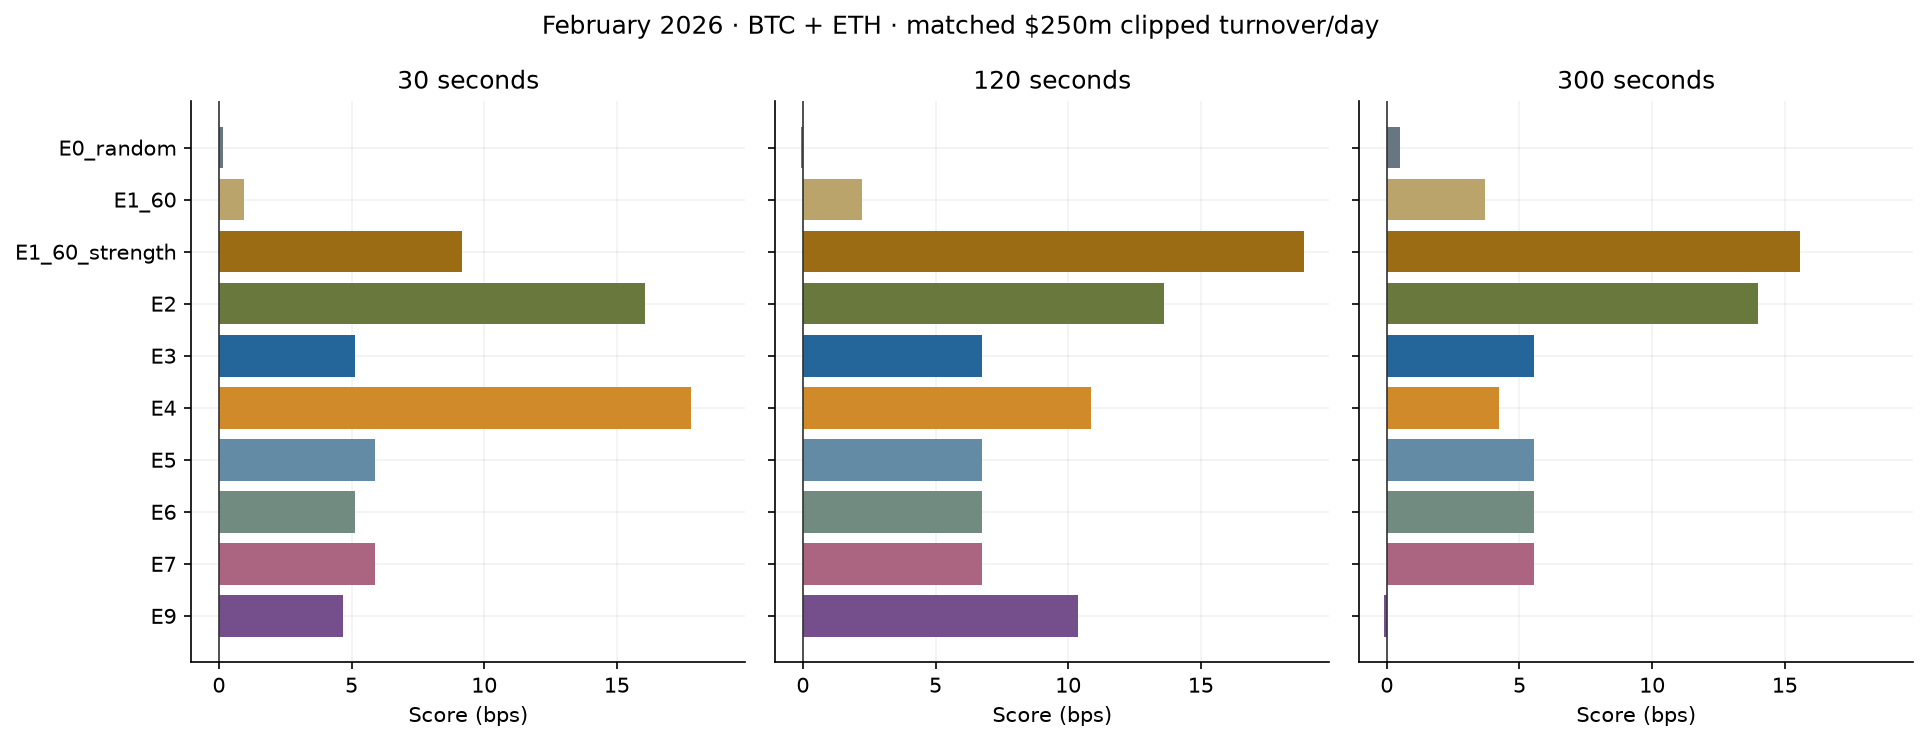

In [2]:
display(report.score_matrix())
show(report.score_figure(),'strategy_scores.png')

In [3]:
primary=report.primary()
display(primary[['model','tau','score','pnl_all','pnl_kept','pnl_filtered','kept_turnover_per_day',
                 'ci_low','ci_high','bootstrap_finite_fraction']])
assert primary.official_turnover_constraint.all()

,model,tau,score,pnl_all,pnl_kept,pnl_filtered,kept_turnover_per_day,ci_low,ci_high,bootstrap_finite_fraction
31,E0_random,30,0.161330,-0.046409,0.114921,-0.047908,"250,000,489.676382",-0.440060,0.889539,1.000000
39,E0_random,120,-0.081000,-0.032564,-0.113564,-0.031812,"250,002,246.198882",-0.786582,0.744933,1.000000
47,E0_random,300,0.497358,0.024532,0.521891,0.019913,"250,000,862.589005",-0.510904,1.685612,1.000000
103,E1,30,1.587292,-0.046409,1.540883,-0.061151,"250,000,152.477010",-0.560812,4.145614,1.000000
111,E1,120,2.601839,-0.032564,2.569274,-0.056728,"250,000,005.652615",0.404334,4.621842,1.000000
...,...,...,...,...,...,...,...,...,...,...
543,E7,120,6.735727,-0.032564,6.703163,-0.095121,"250,000,505.058242",4.227635,8.148658,1.000000
551,E7,300,5.531530,0.024532,5.556062,-0.026842,"250,000,074.445579",1.406095,8.195402,1.000000
787,E9,30,4.691114,-0.046409,4.644704,-0.089977,"250,000,640.852053",1.709864,8.572017,1.000000
795,E9,120,10.377586,-0.032564,10.345022,-0.128944,"250,000,001.786071",6.184224,14.913678,1.000000


## Confidence intervals and attribution limits
Pointwise Score intervals use whole UTC days. Paired ablations include moving/circular 5-day block sensitivity and
declared multiplicity adjustments. At very small budgets some resamples retain no trades; nominal intervals are then
missing. Conditional quantiles are kept in the CSV, but are not plotted as nominal 95% confidence intervals.

In [4]:
expanded=report.table('maker','expanded_paired_comparisons.csv')
display(expanded.query("scope=='combined' and block_days==5 and comparator=='E1_60_strength'"))
small=report.table('maker','validation_report.csv')
display(small.loc[small.bootstrap_finite_fraction.lt(1),[
    'model','symbol','tau','budget_per_day','ci_low','ci_high','ci_status']].head(8))

,block_days,scope,tau,model,comparator,delta_score,ci_low,ci_high,finite_bootstrap_fraction,confidence_level,interpretation
126,5,combined,30,E7,E1_60_strength,-3.285822,-9.861657,4.654234,1.000000,0.997917,source-informed expanded family; retrospective...
134,5,combined,120,E7,E1_60_strength,-12.158191,-24.586438,6.917456,1.000000,0.997917,source-informed expanded family; retrospective...
142,5,combined,300,E7,E1_60_strength,-10.053966,-28.126816,10.116149,1.000000,0.997917,source-informed expanded family; retrospective...


,model,symbol,tau,budget_per_day,ci_low,ci_high,ci_status
72,E1,btcusdt,30,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
80,E1,btcusdt,120,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
88,E1,btcusdt,300,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
96,E1,combined,30,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
104,E1,combined,120,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
112,E1,combined,300,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
120,E1,ethusdt,30,"500,000.000000",NaN,NaN,some draws retain no trades; conditional quant...
122,E1,ethusdt,30,"750,000.000000",NaN,NaN,some draws retain no trades; conditional quant...


## Turnover and daily stability
Matching the full month's average does not guarantee steady daily participation. Daily Score is undefined on a day
with no retained weight. Those gaps remain missing rather than being replaced by zero.

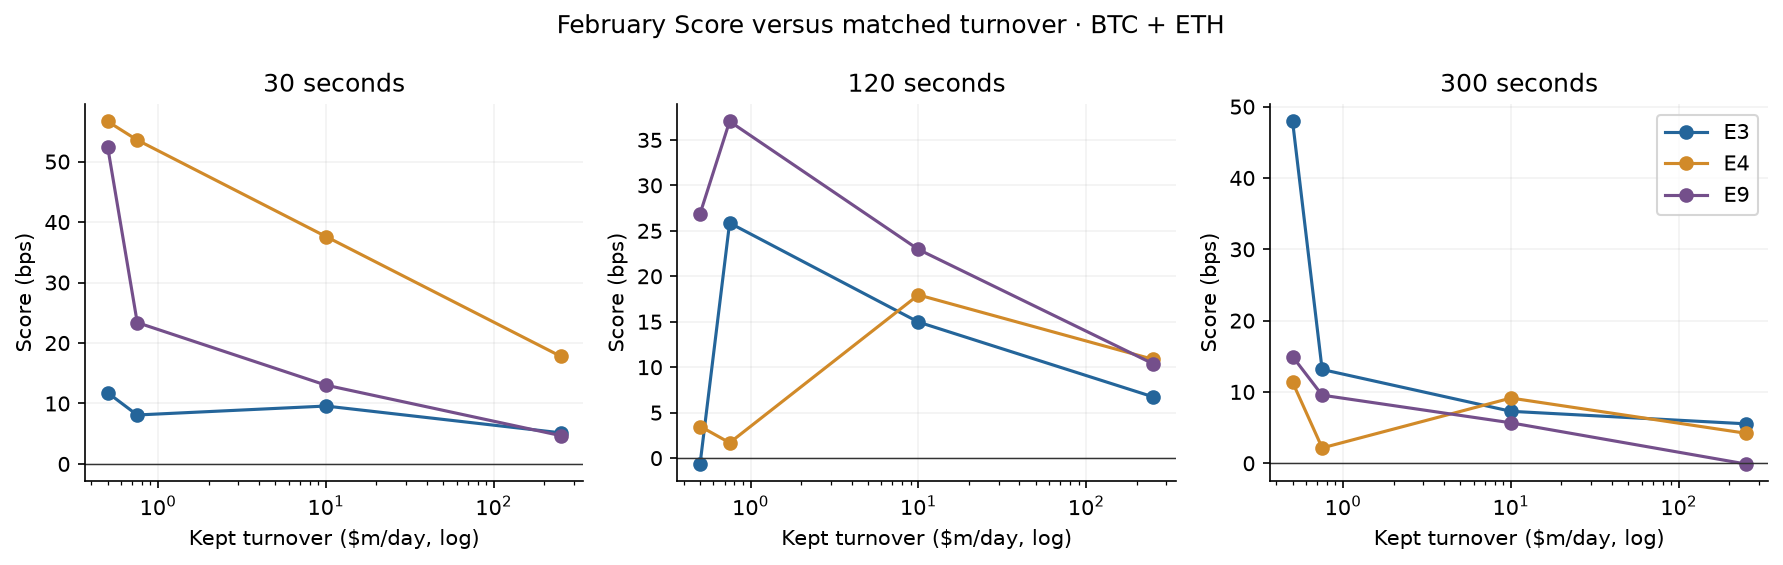

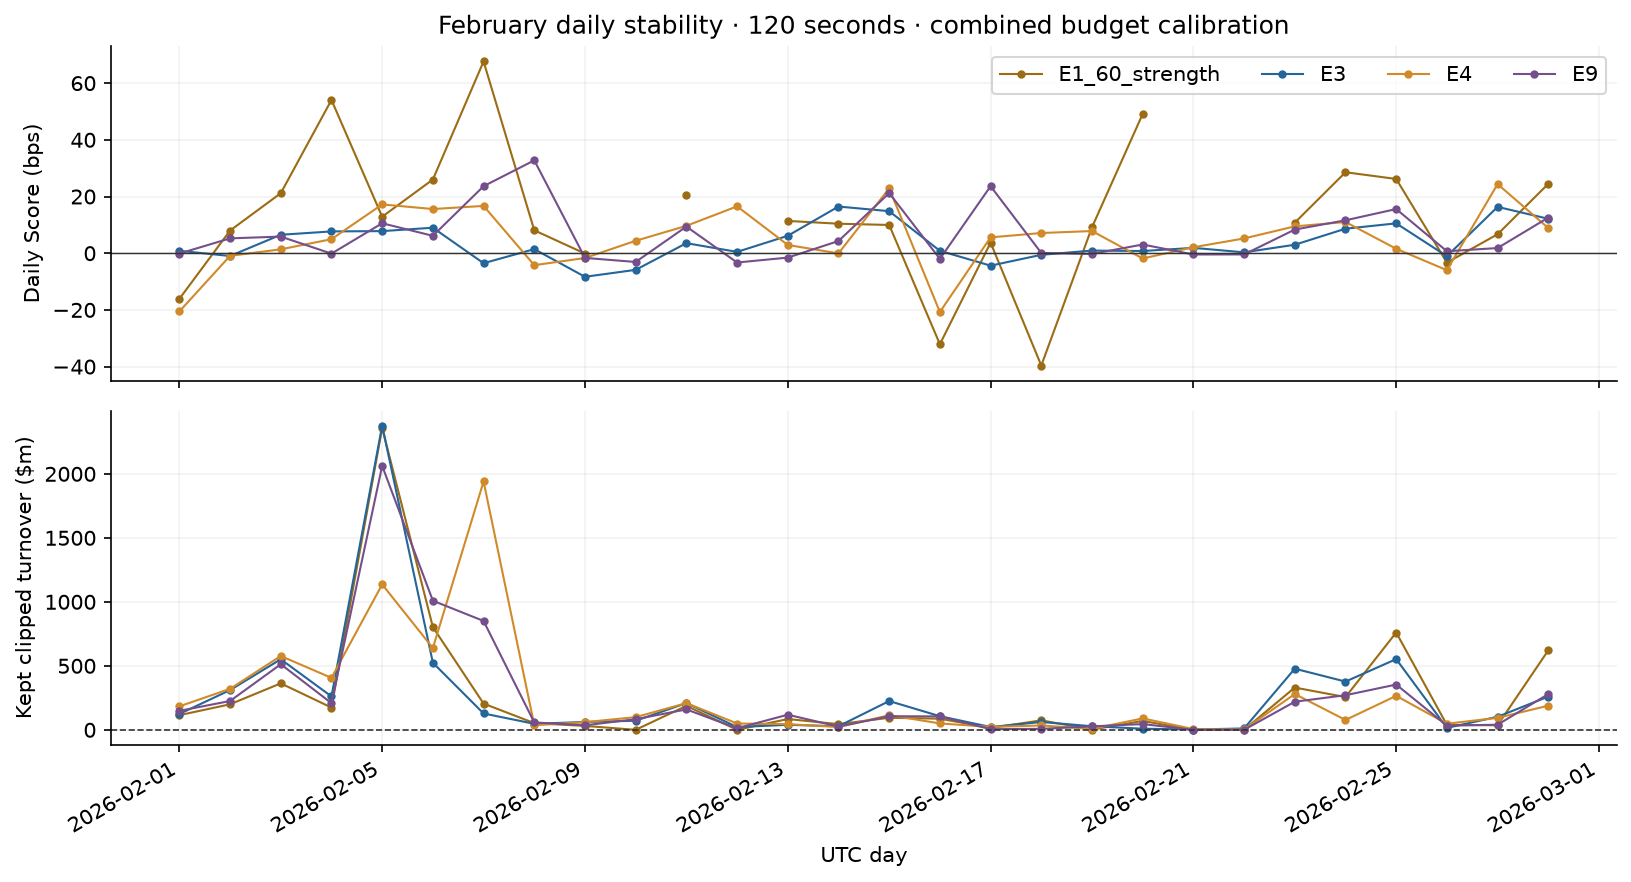

In [5]:
show(report.turnover_figure(),'score_turnover.png')
show(report.daily_figure(),'daily_stability.png')

In [6]:
display(primary[['model','tau','days_with_kept_trades','minimum_daily_kept_turnover',
                 'fraction_days_below_500k','largest_day_share_of_kept_turnover','score_without_best_day']])
daily=report.daily_primary()
assert not daily.duplicated(['model','day']).any()
# Independent reconstruction of the monthly Score from daily sufficient statistics.
for model,g in daily.groupby('model'):
    total=g[['kept_w','kept_wy','all_w','all_wy']].sum()
    score=total.kept_wy/total.kept_w-total.all_wy/total.all_w
    expected=primary.query('model==@model and tau==120').score.iloc[0]
    np.testing.assert_allclose(score,expected,rtol=1e-11)

,model,tau,days_with_kept_trades,minimum_daily_kept_turnover,fraction_days_below_500k,largest_day_share_of_kept_turnover,score_without_best_day
31,E0_random,30,28.000000,"66,001,487.847450",0.000000,0.093470,-0.070220
39,E0_random,120,28.000000,"66,001,487.847450",0.000000,0.093470,-0.226487
47,E0_random,300,28.000000,"66,001,487.847450",0.000000,0.093470,0.231559
103,E1,30,28.000000,"31,324,401.986170",0.000000,0.143368,0.549987
111,E1,120,28.000000,"31,324,401.986170",0.000000,0.143369,1.881613
...,...,...,...,...,...,...,...
543,E7,120,28.000000,"2,347,910.208300",0.000000,0.339406,6.138545
551,E7,300,27.000000,0.000000,0.035714,0.286790,4.079293
787,E9,30,28.000000,"1,498.292400",0.035714,0.285443,4.903674
795,E9,120,28.000000,"42,214.957100",0.071429,0.294616,10.258158


## January thresholds transferred to February
This comparison freezes January holdout thresholds and reports actual February turnover.
It cannot be read as another matched-$250m/day ranking. Fixed thresholds never guarantee future turnover.

In [7]:
transfer=report.table('maker','threshold_transfer_report.csv').query("scope=='combined' and budget_per_day==250000000")
display(transfer[['model','tau','score','kept_turnover_per_day','official_turnover_constraint']])
display(report.table('catboost','v1/threshold_transfer_report.csv')[
    ['model','tau','score','kept_turnover_per_day','fraction_days_below_500k']])

,model,tau,score,kept_turnover_per_day,official_turnover_constraint
11,E2,30,4.870826,"1,024,254,114.414468",True
14,E2,120,3.382340,"1,550,197,509.815431",True
17,E2,300,10.438306,"377,318,444.405936",True
38,E3,30,5.425766,"236,827,542.346587",True
41,E3,120,6.658896,"212,262,532.468485",True
44,E3,300,13.876041,"30,741,545.386057",True
65,E7,30,5.998161,"139,198,644.633268",True
68,E7,120,10.893344,"47,520,597.537133",True
71,E7,300,13.876041,"30,741,545.386057",True


,model,tau,score,kept_turnover_per_day,fraction_days_below_500k
0,E9,30,7.559702,"132,538,583.901785",0.214286
1,E9,120,16.757265,"99,264,634.768322",0.107143
2,E9,300,5.462111,"31,312,599.232310",0.500000


## Stale quotes and liquidation price sensitivity
The official label forward-fills the last available BBO even when stale. A fresh-quote diagnostic and a separate
liquidation-price cleaning sensitivity are reported without silently redefining the official scorer.

In [8]:
display(primary.query("model in ['E3','E4','E7','E9']")[
    ['model','tau','score','fresh_future_quote_score','kept_stale_weight_fraction']])
display(report.table('maker','liquidation_price_audit.csv'))
display(report.table('maker','price_cleaning_sensitivity_summary.csv'))

,model,tau,score,fresh_future_quote_score,kept_stale_weight_fraction
247,E3,30,5.148496,5.148551,0.000000
255,E3,120,6.735727,6.735769,0.000000
263,E3,300,5.531530,5.531460,0.000000
319,E4,30,17.811140,17.811196,0.000000
327,E4,120,10.861847,10.861890,0.000000
335,E4,300,4.211977,4.211907,0.000000
535,E7,30,5.876502,5.876557,0.000000
543,E7,120,6.735727,6.735769,0.000000
551,E7,300,5.531530,5.531460,0.000000
787,E9,30,4.691114,4.691169,0.000000


,symbol,exchange,rows,fresh_reference_rows,flagged_300bps,flagged_1000bps,flagged_raw_notional
0,btcusdt,binance,114255,113836,11,2,"2,842.777200"
1,btcusdt,bybit,228655,222034,1,0,"1,950.000000"
2,ethusdt,binance,131769,131319,36,11,"3,397,156.612670"
3,ethusdt,bybit,160214,155845,3,1,"11,988.198300"


,symbol,tau,raw_price_score,flagged_removed_score,delta_score,changed_decisions
0,btcusdt,30,0.372053,0.372033,-0.000020,1084
1,btcusdt,120,0.609998,0.609943,-0.000056,1084
2,btcusdt,300,1.252878,1.253006,0.000127,1084
3,combined,30,0.500443,0.500344,-0.000098,7939
4,combined,120,0.997774,0.997771,-0.000003,7939
5,combined,300,1.675191,1.675118,-0.000073,7939
6,ethusdt,30,0.630182,0.629994,-0.000188,6855
7,ethusdt,120,1.411392,1.411440,0.000048,6855
8,ethusdt,300,2.123674,2.123374,-0.000300,6855


## Conclusion
The fixed experiments, controlled ablations and retrospective robustness checks are complete in the original workspace.
These notebooks replay the published aggregate evidence and API examples without refitting.
A fresh hidden period and an execution-aware simulator remain future work. Historical maker markout assumes hypothetical
participation in the kept prints; it is not realized trading profit and contains no inventory, queue position,
latency-aware order placement or cancellation simulation.